# Fashion-MNIST GAN (fixed and sped up)
Changes from the original are marked with `# FIX` or `# SPEED` comments.

## 1. Setup

In [1]:
import os
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
from matplotlib import pyplot as plt

# SPEED: confirm a GPU is actually being used (Colab: Runtime > Change runtime type > GPU)
gpus = tf.config.list_physical_devices('GPU')
print("GPUs:", gpus)
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

# Hyperparameters in one place
LATENT_DIM = 128
BATCH_SIZE = 256      # SPEED: larger batch = better GPU use. Drop to 128 if you run out of memory
EPOCHS = 10           # 10 is only a smoke test; real quality needs 100+ epochs

GPUs: []


## 2. Load and build the dataset

In [2]:
# FIX: Install missing dependency for tensorflow-datasets in this Python environment
!pip install -q importlib_resources

# FIX: the dataset was loaded 3 times in the original notebook. Load and build it once.
def scale_images(data):
    # FIX: explicit cast to float32 before scaling to [0, 1]
    return tf.cast(data['image'], tf.float32) / 255.0

ds = tfds.load('fashion_mnist', split='train')
ds = (ds
      .map(scale_images, num_parallel_calls=tf.data.AUTOTUNE)  # SPEED: parallel preprocessing
      .cache()                                                 # SPEED: cache after the map, before shuffle
      .shuffle(10000)
      .batch(BATCH_SIZE, drop_remainder=True)                  # FIX: fixed batch size avoids a ragged last batch
      .prefetch(tf.data.AUTOTUNE))                             # SPEED: was prefetch(64)

print(ds.element_spec)

TensorSpec(shape=(256, 28, 28, 1), dtype=tf.float32, name=None)


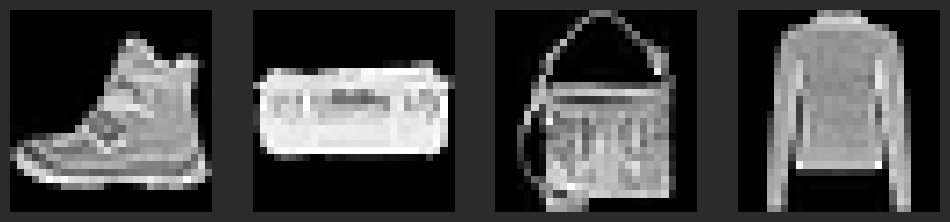

In [3]:
# Quick look at a few real images
batch = next(iter(ds))
fig, ax = plt.subplots(ncols=4, figsize=(12, 3))
for i in range(4):
    ax[i].imshow(np.squeeze(batch[i].numpy()), cmap='gray')
    ax[i].axis('off')
plt.show()

## 3. Build the networks

In [4]:
# FIX: the original had a typo here: "tensorflowU.keras"
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Input, Conv2D, Dense, Flatten, Reshape,
                                     LeakyReLU, Dropout, UpSampling2D)

### 3.1 Generator

In [5]:
def build_generator():
    model = Sequential(name="generator")
    # FIX: latent input is a flat vector of size 128, not (128, 1)
    model.add(Input(shape=(LATENT_DIM,)))
    model.add(Dense(7 * 7 * 128))
    model.add(LeakyReLU(0.2))
    model.add(Reshape((7, 7, 128)))

    # Upsampling block 1: 7x7 -> 14x14
    model.add(UpSampling2D())
    model.add(Conv2D(128, 5, padding='same'))
    model.add(LeakyReLU(0.2))

    # Upsampling block 2: 14x14 -> 28x28
    model.add(UpSampling2D())
    model.add(Conv2D(128, 5, padding='same'))
    model.add(LeakyReLU(0.2))

    # Convolutional blocks
    model.add(Conv2D(128, 4, padding='same'))
    model.add(LeakyReLU(0.2))
    model.add(Conv2D(128, 4, padding='same'))
    model.add(LeakyReLU(0.2))

    # One channel output in [0, 1]
    model.add(Conv2D(1, 7, padding='same', activation='sigmoid'))
    return model

generator = build_generator()
generator.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       809,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 14, 14, 128)    │       409,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 128)    │       409,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,159,361 (8.24 MB)

 Trainable params: 2,159,361 (8.24 MB)

 Non-trainable params: 0 (0.00 B)

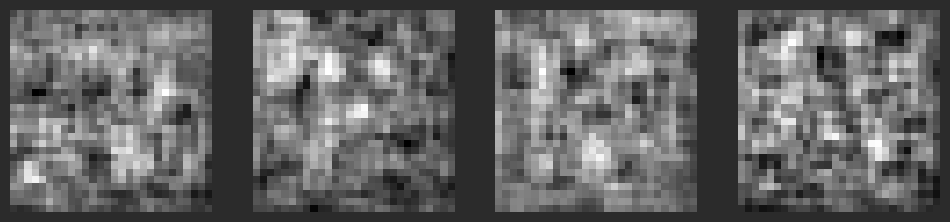

In [6]:
# Sanity check: untrained generator output (should look like noise)
z = tf.random.normal((4, LATENT_DIM))
imgs = generator(z, training=False).numpy()
fig, ax = plt.subplots(ncols=4, figsize=(12, 3))
for i in range(4):
    ax[i].imshow(np.squeeze(imgs[i]), cmap='gray')
    ax[i].axis('off')
plt.show()

### 3.2 Discriminator

In [7]:
def build_discriminator():
    model = Sequential(name="discriminator")
    model.add(Input(shape=(28, 28, 1)))

    for filters in (32, 64, 128, 256):
        model.add(Conv2D(filters, 5))
        model.add(LeakyReLU(0.2))
        model.add(Dropout(0.4))

    model.add(Flatten())
    model.add(Dropout(0.4))
    model.add(Dense(1, activation='sigmoid'))
    return model

discriminator = build_discriminator()
discriminator.summary()

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 20, 20, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 12, 12, 256)    │       819,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        36,865 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,113,345 (4.25 MB)

 Trainable params: 1,113,345 (4.25 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# FIX: the original reshaped a leftover loop variable. Test with the generated batch directly.
print(discriminator(imgs, training=False).numpy().ravel())

[0.50028765 0.50031745 0.50032103 0.50049174]


## 4. Training loop

### 4.1 Losses and optimizers

In [9]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy

g_opt = Adam(learning_rate=0.0001)
d_opt = Adam(learning_rate=0.00001)   # FIX: discriminator learns slower so it doesn't overpower the generator
g_loss = BinaryCrossentropy()
d_loss = BinaryCrossentropy()

### 4.2 Subclassed GAN model

In [10]:
class FashionGAN(Model):
    def __init__(self, generator, discriminator, latent_dim=LATENT_DIM, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.generator = generator
        self.discriminator = discriminator
        self.latent_dim = latent_dim

    def compile(self, g_opt, d_opt, g_loss, d_loss, *args, **kwargs):
        super().compile(*args, **kwargs)
        self.g_opt = g_opt
        self.d_opt = d_opt
        self.g_loss = g_loss
        self.d_loss = d_loss

    # Note: Keras already wraps train_step in a tf.function, so no extra decorator is needed.
    def train_step(self, real_images):
        # FIX: batch size is read from the data. The original hard-coded 128,
        # which crashes with any other batch size or a smaller final batch.
        batch_size = tf.shape(real_images)[0]

        # ---- Train the discriminator ----
        fake_images = self.generator(
            tf.random.normal((batch_size, self.latent_dim)), training=False)

        with tf.GradientTape() as d_tape:
            yhat_real = self.discriminator(real_images, training=True)
            yhat_fake = self.discriminator(fake_images, training=True)
            yhat_realfake = tf.concat([yhat_real, yhat_fake], axis=0)

            # FIX: conventional labels (real = 1, fake = 0) with label smoothing noise.
            # The original used inverted labels; this is equivalent but easier to follow.
            y_real = tf.ones_like(yhat_real) - 0.15 * tf.random.uniform(tf.shape(yhat_real))
            y_fake = tf.zeros_like(yhat_fake) + 0.15 * tf.random.uniform(tf.shape(yhat_fake))
            y_realfake = tf.concat([y_real, y_fake], axis=0)

            total_d_loss = self.d_loss(y_realfake, yhat_realfake)

        dgrad = d_tape.gradient(total_d_loss, self.discriminator.trainable_variables)
        self.d_opt.apply_gradients(zip(dgrad, self.discriminator.trainable_variables))

        # ---- Train the generator ----
        with tf.GradientTape() as g_tape:
            gen_images = self.generator(
                tf.random.normal((batch_size, self.latent_dim)), training=True)
            predicted_labels = self.discriminator(gen_images, training=False)
            # Generator wants the discriminator to say "real" (1)
            total_g_loss = self.g_loss(tf.ones_like(predicted_labels), predicted_labels)

        ggrad = g_tape.gradient(total_g_loss, self.generator.trainable_variables)
        self.g_opt.apply_gradients(zip(ggrad, self.generator.trainable_variables))

        return {"d_loss": total_d_loss, "g_loss": total_g_loss}

In [11]:
fashgan = FashionGAN(generator, discriminator)
fashgan.compile(g_opt, d_opt, g_loss, d_loss)

### 4.3 Callback

In [12]:
from tensorflow.keras.preprocessing.image import array_to_img
from tensorflow.keras.callbacks import Callback

class ModelMonitor(Callback):
    # SPEED: `every` saves images every N epochs instead of every epoch
    def __init__(self, num_img=3, latent_dim=LATENT_DIM, every=5):
        super().__init__()
        self.num_img = num_img
        self.latent_dim = latent_dim
        self.every = every

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every != 0:
            return
        # FIX: normal noise (matches training) and a flat latent vector, not uniform with shape (n, 128, 1)
        z = tf.random.normal((self.num_img, self.latent_dim))
        # FIX: the original called .numpy() without assigning the result
        generated_images = (self.model.generator(z, training=False) * 255).numpy()
        for i in range(self.num_img):
            img = array_to_img(generated_images[i])
            img.save(os.path.join('images', f'generated_img_{epoch + 1}_{i}.png'))

### 4.4 Train

In [14]:
os.makedirs('images', exist_ok=True)

# SPEED: verbose=2 prints one line per epoch instead of redrawing a progress bar every step
hist = fashgan.fit(ds, epochs=EPOCHS, callbacks=[ModelMonitor(every=5)])

Epoch 1/10
  2/234 ━━━━━━━━━━━━━━━━━━━━ 18:42 5s/step - d_loss: 0.6943 - g_loss: 0.6917

KeyboardInterrupt: 

### 4.5 Review performance

In [ ]:
plt.suptitle('Loss')
plt.plot(hist.history['d_loss'], label='d_loss')
plt.plot(hist.history['g_loss'], label='g_loss')
plt.legend()
plt.show()

## 5. Test the generator

In [ ]:
imgs = generator.predict(tf.random.normal((16, LATENT_DIM)), verbose=0)

fig, ax = plt.subplots(ncols=4, nrows=4, figsize=(10, 10))
for r in range(4):
    for c in range(4):
        # FIX: the original index (r+1)*(c+1)-1 repeated images. Use r*4 + c.
        ax[r][c].imshow(np.squeeze(imgs[r * 4 + c]), cmap='gray')
        ax[r][c].axis('off')
plt.show()

### 5.1 Save the models

In [ ]:
# FIX: .h5 is a legacy format. Use the native .keras format.
generator.save('generator.keras')
discriminator.save('discriminator.keras')

# To reload later:
# generator = tf.keras.models.load_model('generator.keras')